In [2]:
import os
import shutil
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import zipfile
from PIL import Image
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Библиотеки импортированы")

Библиотеки импортированы


In [3]:
from google.colab import drive

drive.mount('/content/drive')
zip_path = '/content/drive/MyDrive/archive.zip'
extract_path = '/content/dataset_raw'

if not os.path.exists(extract_path):
    print("Распаковка архива")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Архив распакован!")
else:
    print("Папка уже существует, пропускаем распаковку.")

print("\n Содержимое распакованной папки:")
print(os.listdir(extract_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Распаковка архива
Архив распакован!

 Содержимое распакованной папки:
['Mushrooms', 'mushrooms']


In [4]:
print("'mushrooms':")
print(os.listdir('/content/dataset_raw/mushrooms'))

print("\n'Mushrooms':")
print(os.listdir('/content/dataset_raw/Mushrooms'))

'mushrooms':
['Mushrooms']

'Mushrooms':
['Hygrocybe', 'Russula', 'Suillus', 'Lactarius', 'Agaricus', 'Entoloma', 'Boletus', 'Cortinarius', 'Amanita']


In [5]:


RAW_DATA_DIR = '/content/dataset_raw/mushrooms/Mushrooms'
SPLIT_DATA_DIR = '/content/dataset_split'

if os.path.exists(SPLIT_DATA_DIR):
    shutil.rmtree(SPLIT_DATA_DIR)

os.makedirs(os.path.join(SPLIT_DATA_DIR, 'train'), exist_ok=True)
os.makedirs(os.path.join(SPLIT_DATA_DIR, 'test'), exist_ok=True)

classes = [d for d in os.listdir(RAW_DATA_DIR) if os.path.isdir(os.path.join(RAW_DATA_DIR, d))]
print(f" Найдено {len(classes)} классов грибов: {classes}")

for cls in classes:
    cls_path = os.path.join(RAW_DATA_DIR, cls)

    os.makedirs(os.path.join(SPLIT_DATA_DIR, 'train', cls), exist_ok=True)
    os.makedirs(os.path.join(SPLIT_DATA_DIR, 'test', cls), exist_ok=True)

    files = [f for f in os.listdir(cls_path) if os.path.isfile(os.path.join(cls_path, f))]
    random.shuffle(files)

    split_idx = int(len(files) * 0.8)

    for f in files[:split_idx]:
        shutil.copy(os.path.join(cls_path, f), os.path.join(SPLIT_DATA_DIR, 'train', cls, f))
    for f in files[split_idx:]:
        shutil.copy(os.path.join(cls_path, f), os.path.join(SPLIT_DATA_DIR, 'test', cls, f))

print(f"   Train выборка: {sum(len(os.listdir(os.path.join(SPLIT_DATA_DIR, 'train', c))) for c in classes)} изображений")
print(f"   Test выборка:  {sum(len(os.listdir(os.path.join(SPLIT_DATA_DIR, 'test', c))) for c in classes)} изображений")

 Найдено 9 классов грибов: ['Hygrocybe', 'Russula', 'Suillus', 'Lactarius', 'Agaricus', 'Entoloma', 'Boletus', 'Cortinarius', 'Amanita']
   Train выборка: 5367 изображений
   Test выборка:  1347 изображений


In [6]:
data_dir = SPLIT_DATA_DIR

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'test']
}

dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=32, shuffle=True, num_workers=0)
    for x in ['train', 'test']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}
class_names = image_datasets['train'].classes

print(f" Train samples: {dataset_sizes['train']}")
print(f" Test samples: {dataset_sizes['test']}")
print(f" Количество классов: {len(class_names)}")
print(f"️ Классы: {class_names}")

 Train samples: 5367
 Test samples: 1347
 Количество классов: 9
️ Классы: ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


In [7]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f" Используемое устройство: {device}")

model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, len(class_names))

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.Adam(model_ft.parameters(), lr=0.001)

print(f" Входной слой: {num_ftrs}")
print(f" Выходной слой: {len(class_names)} классов")

 Используемое устройство: cuda:0
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


 Входной слой: 512
 Выходной слой: 9 классов


In [8]:
def train_model(model, criterion, optimizer, num_epochs=10):
    history = {
        'train_loss': [],
        'train_acc': [],
        'test_loss': [],
        'test_acc': []
    }

    for epoch in range(num_epochs):
        print(f'\n Эпоха {epoch+1}/{num_epochs}')
        print('-' * 30)

        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}')

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

    return model, history

print("Начало обучения...")
model_ft, history = train_model(model_ft, criterion, optimizer_ft, num_epochs=10)
print("\n Обучение завершено!")

Начало обучения...

 Эпоха 1/10
------------------------------
train Loss: 1.4579 | Acc: 0.4893
test Loss: 1.3997 | Acc: 0.5471

 Эпоха 2/10
------------------------------
train Loss: 1.1303 | Acc: 0.6080
test Loss: 1.0307 | Acc: 0.6682

 Эпоха 3/10
------------------------------
train Loss: 0.9990 | Acc: 0.6562
test Loss: 1.0038 | Acc: 0.6607

 Эпоха 4/10
------------------------------
train Loss: 0.9385 | Acc: 0.6780
test Loss: 1.0274 | Acc: 0.6815

 Эпоха 5/10
------------------------------
train Loss: 0.8683 | Acc: 0.7000
test Loss: 0.8381 | Acc: 0.7238

 Эпоха 6/10
------------------------------
train Loss: 0.8079 | Acc: 0.7222
test Loss: 1.0780 | Acc: 0.6674

 Эпоха 7/10
------------------------------
train Loss: 0.7666 | Acc: 0.7336
test Loss: 0.7760 | Acc: 0.7335

 Эпоха 8/10
------------------------------
train Loss: 0.7350 | Acc: 0.7472
test Loss: 0.7533 | Acc: 0.7587

 Эпоха 9/10
------------------------------
train Loss: 0.7043 | Acc: 0.7544
test Loss: 0.7394 | Acc: 0.7550


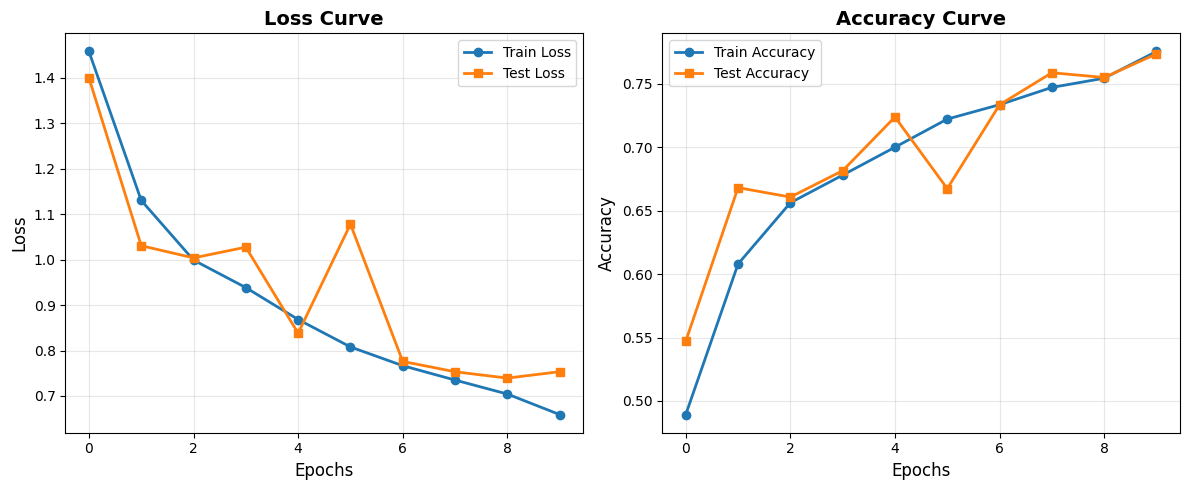

Финальная точность на тестовой выборке: 77.36%


In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o', linewidth=2)
plt.plot(history['test_loss'], label='Test Loss', marker='s', linewidth=2)
plt.title('Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy', marker='o', linewidth=2)
plt.plot(history['test_acc'], label='Test Accuracy', marker='s', linewidth=2)
plt.title('Accuracy Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

final_accuracy = history['test_acc'][-1] * 100
print(f"Финальная точность на тестовой выборке: {final_accuracy:.2f}%")

Генерация предсказаний на тестовой выборке
Предсказания получены

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

    Agaricus       0.65      0.75      0.70        71
     Amanita       0.93      0.67      0.78       150
     Boletus       0.73      0.98      0.83       215
 Cortinarius       0.88      0.62      0.73       168
    Entoloma       0.69      0.67      0.68        73
   Hygrocybe       0.84      0.88      0.85        64
   Lactarius       0.71      0.92      0.80       313
     Russula       0.91      0.65      0.76       230
     Suillus       0.71      0.51      0.59        63

    accuracy                           0.77      1347
   macro avg       0.78      0.74      0.75      1347
weighted avg       0.80      0.77      0.77      1347


CONFUSION MATRIX


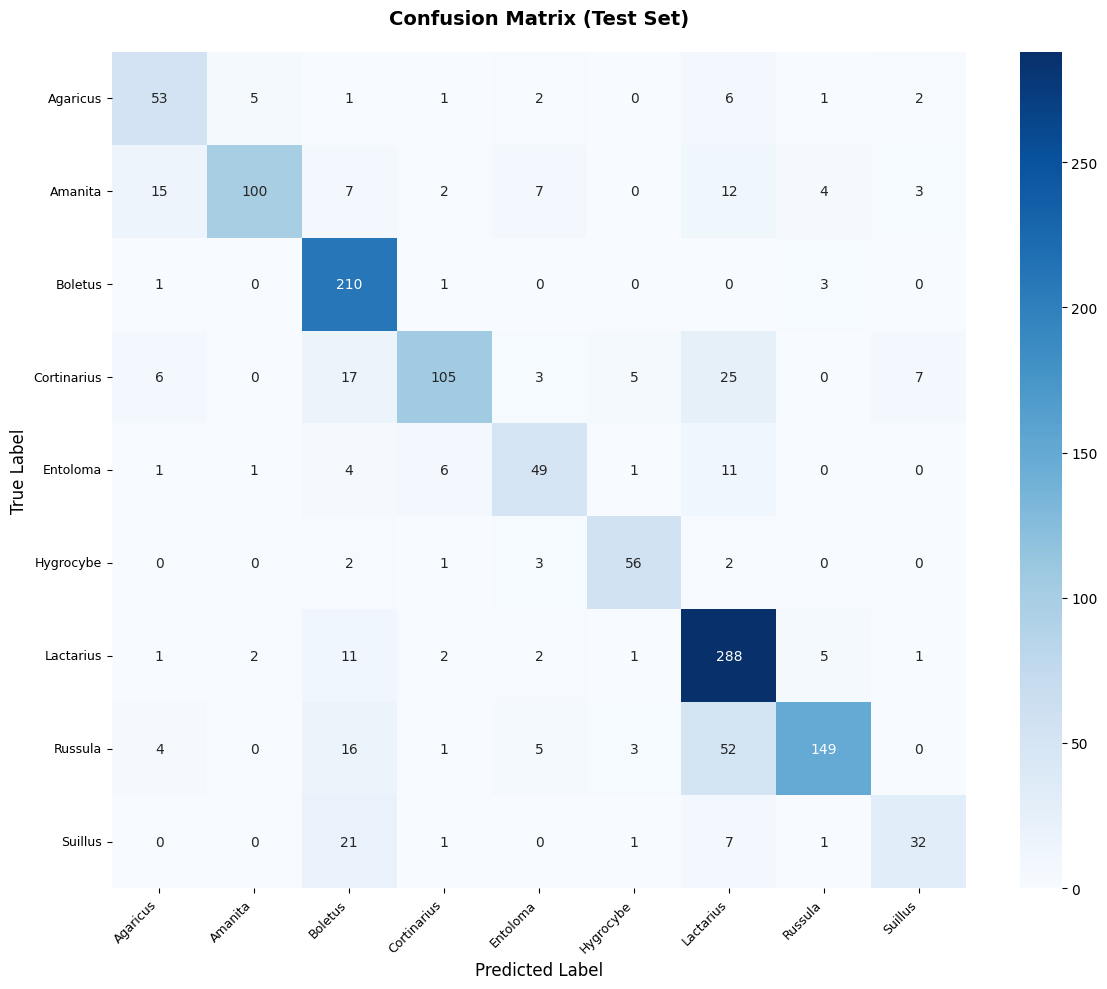


 Правильно классифицировано: 1042/1347
Общая точность (из матрицы): 77.36%


In [10]:
model_ft.eval()

all_preds = []
all_labels = []

print("Генерация предсказаний на тестовой выборке")
with torch.no_grad():
    for inputs, labels in dataloaders['test']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model_ft(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Предсказания получены\n")

print("="*60)
print("CLASSIFICATION REPORT (Test Set)")
print("="*60)
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    zero_division=0
))

print("\n" + "="*60)
print("CONFUSION MATRIX")
print("="*60)

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

total_correct = np.trace(cm)
total_samples = np.sum(cm)
accuracy_from_cm = (total_correct / total_samples) * 100

print(f"\n Правильно классифицировано: {total_correct}/{total_samples}")
print(f"Общая точность (из матрицы): {accuracy_from_cm:.2f}%")

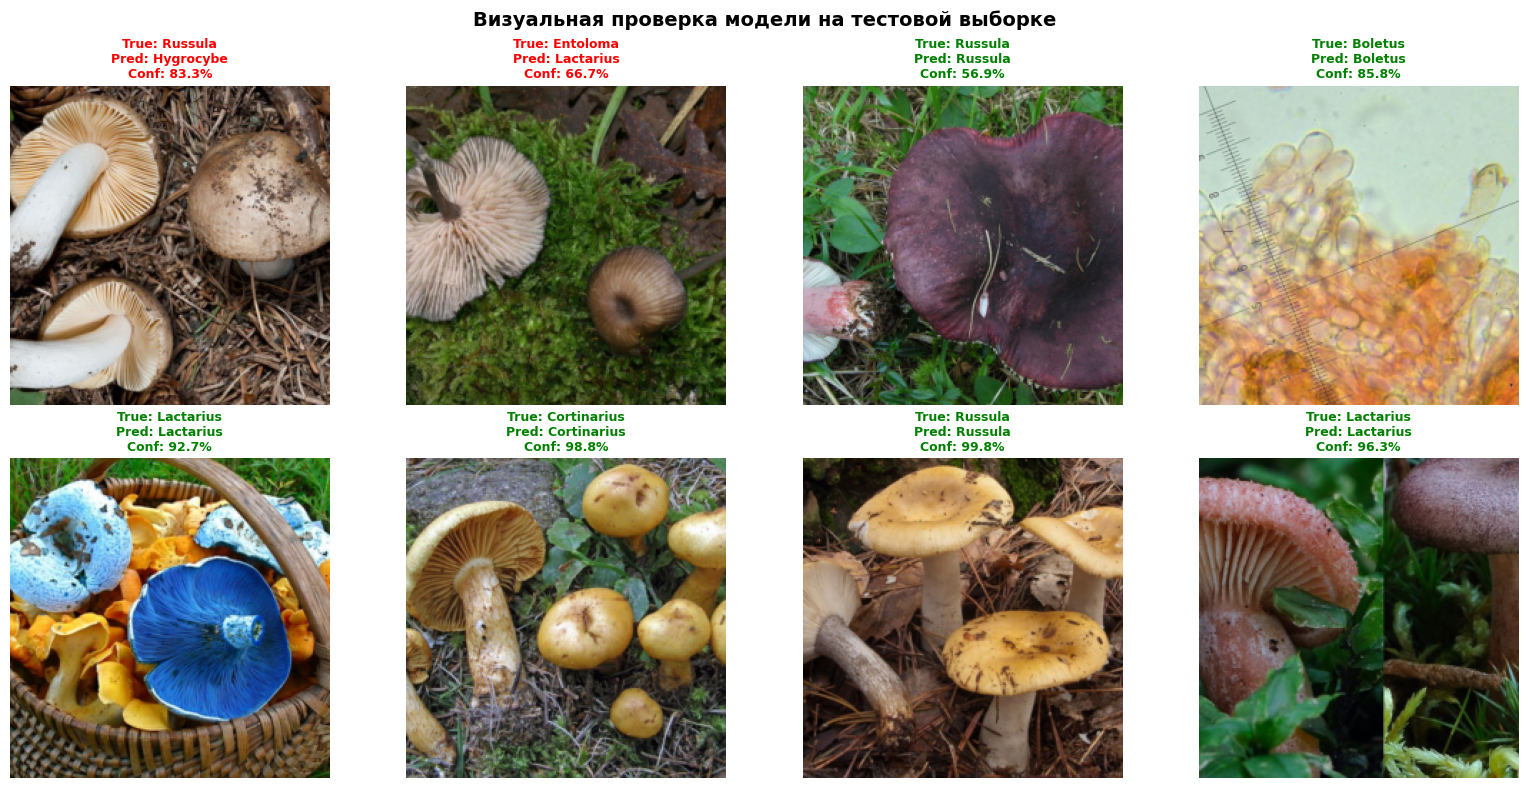


 Правильно угадано на этом батче: 28/8 (350%)


In [11]:
model_ft.eval()

dataiter = iter(dataloaders['test'])
images, labels = next(dataiter)

images_device = images.to(device)
labels_device = labels.to(device)

with torch.no_grad():
    outputs = model_ft(images_device)
    probs = torch.nn.functional.softmax(outputs, dim=1)
    _, preds = torch.max(outputs, 1)

def denormalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx in range(8):
    img = denormalize(images[idx].cpu())
    img_np = img.numpy().transpose(1, 2, 0)
    img_np = np.clip(img_np, 0, 1)

    true_label = class_names[labels[idx].item()]
    pred_label = class_names[preds[idx].item()]
    confidence = probs[idx][preds[idx]].item() * 100

    axes[idx].imshow(img_np)

    color = 'green' if true_label == pred_label else 'red'
    axes[idx].set_title(
        f"True: {true_label}\nPred: {pred_label}\nConf: {confidence:.1f}%",
        color=color,
        fontsize=9,
        fontweight='bold'
    )
    axes[idx].axis('off')

plt.suptitle('Визуальная проверка модели на тестовой выборке', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

correct = (preds.cpu() == labels).sum().item()
print(f"\n Правильно угадано на этом батче: {correct}/8 ({correct/8*100:.0f}%)")